In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from sklearn.metrics import (
     accuracy_score,
     precision_score,
     recall_score,
     f1_score,
     confusion_matrix,
     classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier,GradientBoostingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

import warnings
warnings.filterwarnings("ignore")


In [12]:
df = pd.read_csv("C:/Users/Admin/Downloads/archive/Application_Data.csv")
df.head()

,Applicant_ID,Applicant_Gender,Owned_Car,Owned_Realty,Total_Children,Total_Income,Income_Type,Education_Type,Family_Status,Housing_Type,...,Owned_Work_Phone,Owned_Phone,Owned_Email,Job_Title,Total_Family_Members,Applicant_Age,Years_of_Working,Total_Bad_Debt,Total_Good_Debt,Status
0,5008806,M,1,1,0,112500,Working ...,Secondary / secondary special ...,Married ...,House / apartment ...,...,0,0,0,Security staff ...,2,59,4,0,30,1
1,5008808,F,0,1,0,270000,Commercial associate ...,Secondary / secondary special ...,Single / not married ...,House / apartment ...,...,0,1,1,Sales staff ...,1,53,9,0,5,1
2,5008809,F,0,1,0,270000,Commercial associate ...,Secondary / secondary special ...,Single / not married ...,House / apartment ...,...,0,1,1,Sales staff ...,1,53,9,0,5,1
3,5008810,F,0,1,0,270000,Commercial associate ...,Secondary / secondary special ...,Single / not married ...,House / apartment ...,...,0,1,1,Sales staff ...,1,53,9,0,27,1
4,5008811,F,0,1,0,270000,Commercial associate ...,Secondary / secondary special ...,Single / not married ...,House / apartment ...,...,0,1,1,Sales staff ...,1,53,9,0,39,1


In [13]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 25128
Number of Columns: 21


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25128 entries, 0 to 25127
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Applicant_ID          25128 non-null  int64 
 1   Applicant_Gender      25128 non-null  object
 2   Owned_Car             25128 non-null  int64 
 3   Owned_Realty          25128 non-null  int64 
 4   Total_Children        25128 non-null  int64 
 5   Total_Income          25128 non-null  int64 
 6   Income_Type           25128 non-null  object
 7   Education_Type        25128 non-null  object
 8   Family_Status         25128 non-null  object
 9   Housing_Type          25128 non-null  object
 10  Owned_Mobile_Phone    25128 non-null  int64 
 11  Owned_Work_Phone      25128 non-null  int64 
 12  Owned_Phone           25128 non-null  int64 
 13  Owned_Email           25128 non-null  int64 
 14  Job_Title             25128 non-null  object
 15  Total_Family_Members  25128 non-null

In [15]:
df.describe()

,Applicant_ID,Owned_Car,Owned_Realty,Total_Children,Total_Income,Owned_Mobile_Phone,Owned_Work_Phone,Owned_Phone,Owned_Email,Total_Family_Members,Applicant_Age,Years_of_Working,Total_Bad_Debt,Total_Good_Debt,Status
count,2.512800e+04,25128.000000,25128.000000,25128.000000,2.512800e+04,25128.0,25128.000000,25128.000000,25128.000000,25128.000000,25128.000000,25128.000000,25128.000000,25128.000000,25128.000000
mean,5.078835e+06,0.418378,0.654927,0.509472,1.948365e+05,1.0,0.273758,0.292741,0.100684,2.291309,40.995503,7.690903,0.333095,21.057545,0.995185
std,4.194378e+04,0.493303,0.475402,0.762937,1.045211e+05,0.0,0.445895,0.455030,0.300916,0.928871,9.552832,6.415007,1.569448,14.735347,0.069227
min,5.008806e+06,0.000000,0.000000,0.000000,2.700000e+04,1.0,0.000000,0.000000,0.000000,1.000000,21.000000,1.000000,0.000000,1.000000,0.000000
25%,5.042226e+06,0.000000,0.000000,0.000000,1.350000e+05,1.0,0.000000,0.000000,0.000000,2.000000,33.000000,3.000000,0.000000,9.000000,1.000000
50%,5.079004e+06,0.000000,1.000000,0.000000,1.800000e+05,1.0,0.000000,0.000000,0.000000,2.000000,40.000000,6.000000,0.000000,18.000000,1.000000
75%,5.115603e+06,1.000000,1.000000,1.000000,2.250000e+05,1.0,1.000000,1.000000,0.000000,3.000000,48.000000,10.000000,0.000000,31.000000,1.000000
max,5.150487e+06,1.000000,1.000000,5.000000,1.575000e+06,1.0,1.000000,1.000000,1.000000,7.000000,68.000000,44.000000,49.000000,61.000000,1.000000


In [16]:
df.isnull().sum()

Applicant_ID            0
Applicant_Gender        0
Owned_Car               0
Owned_Realty            0
Total_Children          0
Total_Income            0
Income_Type             0
Education_Type          0
Family_Status           0
Housing_Type            0
Owned_Mobile_Phone      0
Owned_Work_Phone        0
Owned_Phone             0
Owned_Email             0
Job_Title               0
Total_Family_Members    0
Applicant_Age           0
Years_of_Working        0
Total_Bad_Debt          0
Total_Good_Debt         0
Status                  0
dtype: int64

In [17]:
df.columns

Index(['Applicant_ID', 'Applicant_Gender', 'Owned_Car', 'Owned_Realty',
       'Total_Children', 'Total_Income', 'Income_Type', 'Education_Type',
       'Family_Status', 'Housing_Type', 'Owned_Mobile_Phone',
       'Owned_Work_Phone', 'Owned_Phone', 'Owned_Email', 'Job_Title',
       'Total_Family_Members', 'Applicant_Age', 'Years_of_Working',
       'Total_Bad_Debt', 'Total_Good_Debt', 'Status'],
      dtype='object')

In [18]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


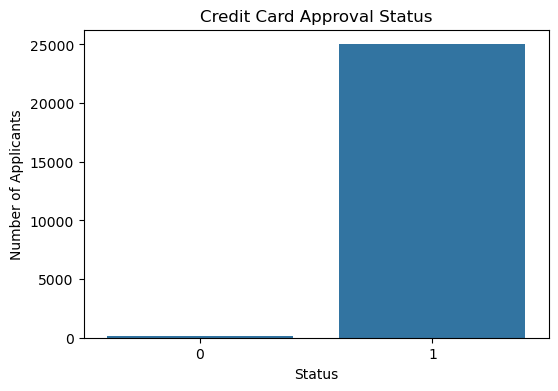

In [19]:
plt.figure(figsize=(6,4))
sns.countplot(x="Status", data=df)
plt.title("Credit Card Approval Status")
plt.xlabel("Status")
plt.ylabel("Number of Applicants")
plt.show()

In [20]:
df = df.drop("Applicant_ID", axis=1)
df.head()

,Applicant_Gender,Owned_Car,Owned_Realty,Total_Children,Total_Income,Income_Type,Education_Type,Family_Status,Housing_Type,Owned_Mobile_Phone,Owned_Work_Phone,Owned_Phone,Owned_Email,Job_Title,Total_Family_Members,Applicant_Age,Years_of_Working,Total_Bad_Debt,Total_Good_Debt,Status
0,M,1,1,0,112500,Working ...,Secondary / secondary special ...,Married ...,House / apartment ...,1,0,0,0,Security staff ...,2,59,4,0,30,1
1,F,0,1,0,270000,Commercial associate ...,Secondary / secondary special ...,Single / not married ...,House / apartment ...,1,0,1,1,Sales staff ...,1,53,9,0,5,1
2,F,0,1,0,270000,Commercial associate ...,Secondary / secondary special ...,Single / not married ...,House / apartment ...,1,0,1,1,Sales staff ...,1,53,9,0,5,1
3,F,0,1,0,270000,Commercial associate ...,Secondary / secondary special ...,Single / not married ...,House / apartment ...,1,0,1,1,Sales staff ...,1,53,9,0,27,1
4,F,0,1,0,270000,Commercial associate ...,Secondary / secondary special ...,Single / not married ...,House / apartment ...,1,0,1,1,Sales staff ...,1,53,9,0,39,1


In [21]:
cat_cols = df.select_dtypes(include="object").columns
for col in cat_cols:
    df[col]=df[col].astype(str).str.strip()
for col in cat_cols:
    print(col,":",df[col].nunique())

Applicant_Gender : 2
Income_Type : 5
Education_Type : 5
Family_Status : 5
Housing_Type : 6
Job_Title : 18


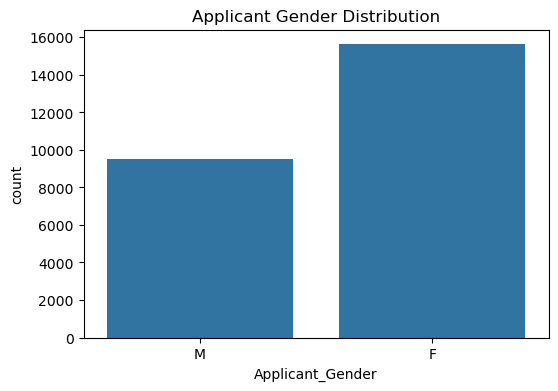

In [22]:
# Gender distribution

plt.figure(figsize=(6,4))
sns.countplot(x="Applicant_Gender", data=df)
plt.title("Applicant Gender Distribution")
plt.show()

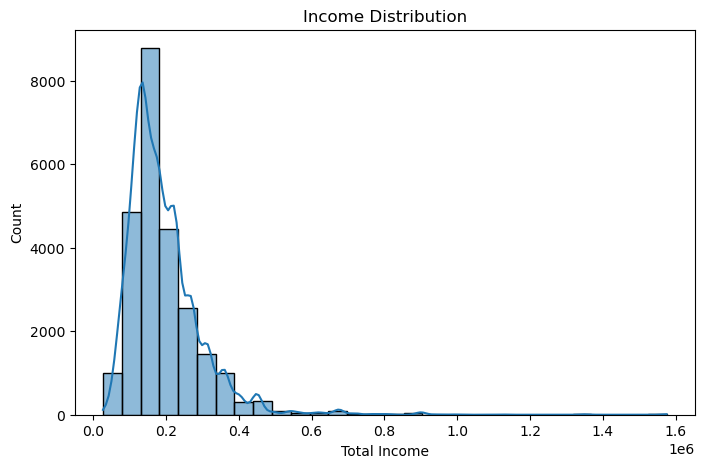

In [23]:
# Income distribution

plt.figure(figsize=(8,5))
sns.histplot(df["Total_Income"], bins=30,kde=True)
plt.title("Income Distribution")
plt.xlabel("Total Income")
plt.show()

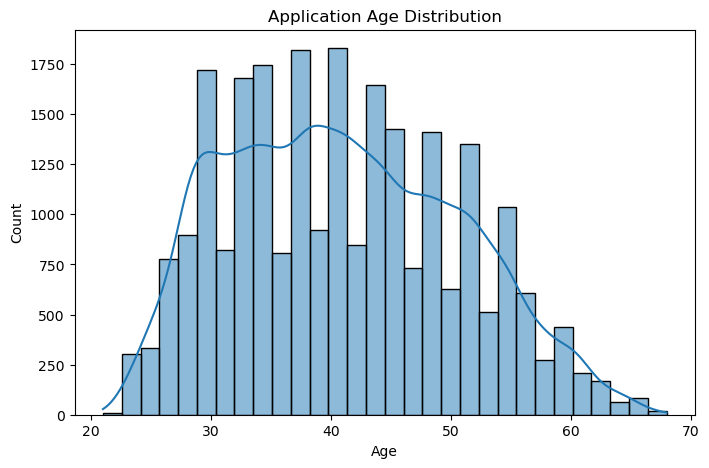

In [24]:
# Age distribution

plt.figure(figsize=(8,5))
sns.histplot(df["Applicant_Age"], bins=30, kde=True)
plt.title("Application Age Distribution")
plt.xlabel("Age")
plt.show()

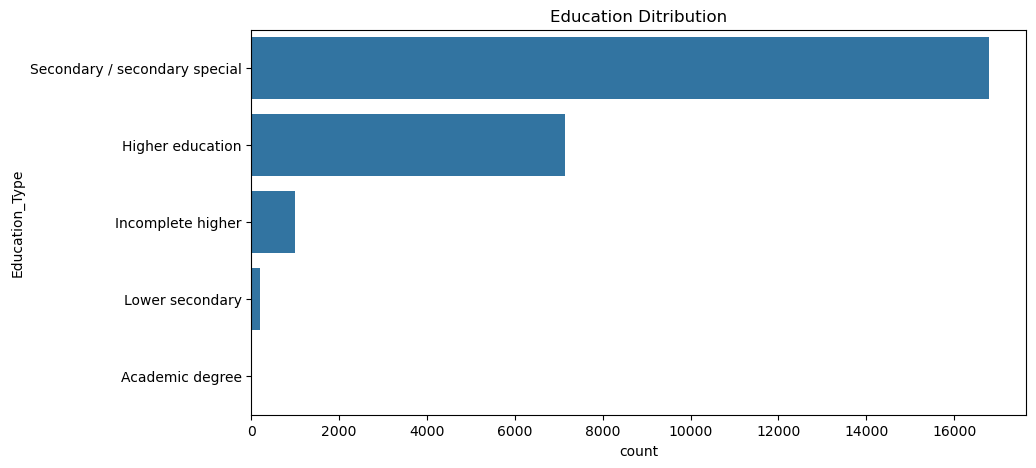

In [25]:
# Education

plt.figure(figsize=(10,5))
sns.countplot(
    y="Education_Type",
    data=df,
    order=df["Education_Type"].value_counts().index)
plt.title("Education Ditribution")
plt.show()

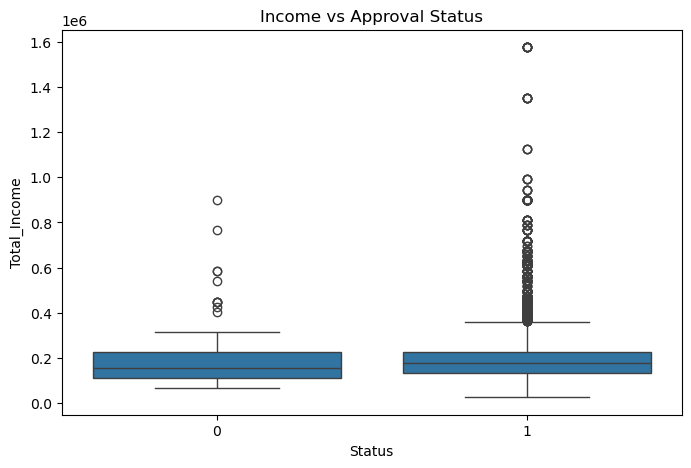

In [26]:
# Income vs Status

plt.figure(figsize=(8,5))
sns.boxplot(
    x="Status",
    y="Total_Income",
    data=df)
plt.title("Income vs Approval Status")
plt.show()

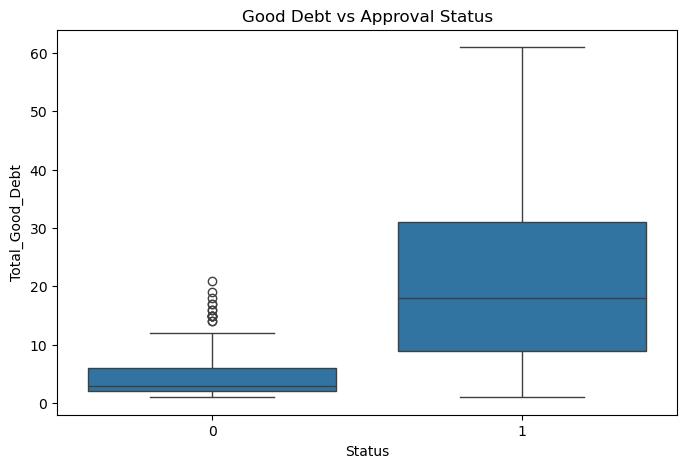

In [27]:
# Good Debt vs Status

plt.figure(figsize=(8,5))
sns.boxplot(
    x="Status",
    y="Total_Good_Debt",
    data=df)
plt.title("Good Debt vs Approval Status")
plt.show()

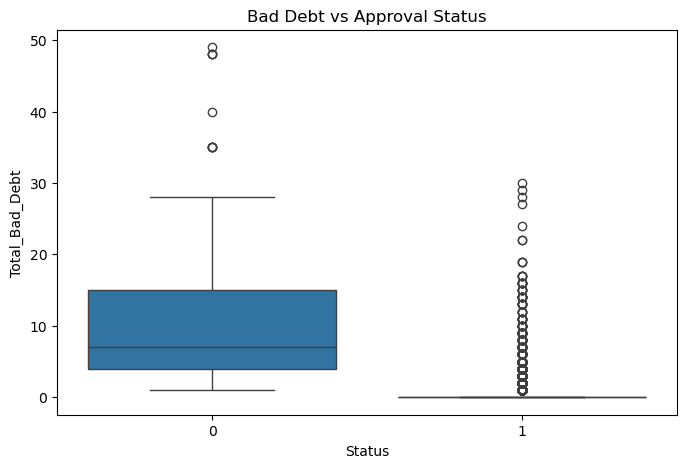

In [28]:
# Bad Debt vs Status

plt.figure(figsize=(8,5))
sns.boxplot(
    x="Status",
    y="Total_Bad_Debt",
    data=df)
plt.title("Bad Debt vs Approval Status")
plt.show()

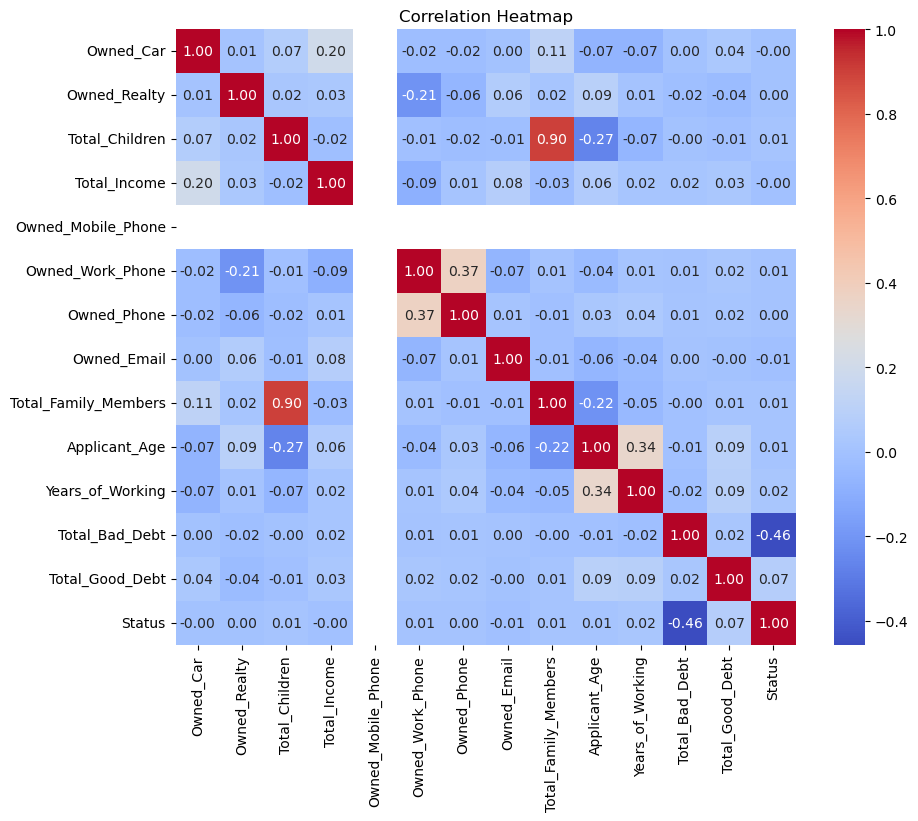

In [29]:
# Correlation Analysis

plt.figure(figsize=(10,8))
numeric_df = df.select_dtypes(include=np.number)
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [30]:
# Feature & Target Separation

X=df.drop("Status", axis=1)
y=df["Status"]
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (25128, 19)
y Shape: (25128,)


In [31]:
# Categorical and Numerical Columns

categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categoraical Columns:")
print(categorical_columns)
print("\nNumerical Columns:")
print(numerical_columns)

Categoraical Columns:
['Applicant_Gender', 'Income_Type', 'Education_Type', 'Family_Status', 'Housing_Type', 'Job_Title']

Numerical Columns:
['Owned_Car', 'Owned_Realty', 'Total_Children', 'Total_Income', 'Owned_Mobile_Phone', 'Owned_Work_Phone', 'Owned_Phone', 'Owned_Email', 'Total_Family_Members', 'Applicant_Age', 'Years_of_Working', 'Total_Bad_Debt', 'Total_Good_Debt']


In [32]:
# Train-Test Split

X_train, X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("X_Train:",X_train.shape)
print("X_Test:",X_test.shape)
print("Y_Train:",y_train.shape)
print("Y_Test:",y_test.shape)

X_Train: (20102, 19)
X_Test: (5026, 19)
Y_Train: (20102,)
Y_Test: (5026,)


In [33]:
# Preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_columns
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_columns
        )
    ]
)


In [35]:
# ========
# Models
# ========

models={
     "Logistic Regression": LogisticRegression(max_iter=500),
     "Decision Tree": DecisionTreeClassifier(random_state=42),
     "KNN": KNeighborsClassifier(n_neighbors=5),
     "Random Forest": RandomForestClassifier(n_estimators=100,random_state=42),
     "Grandient Boosting": GradientBoostingClassifier(random_state=42),
     "SVM" : SVC(kernel="rbf",probability=True),
     "Navie Bayes": GaussianNB()
}
     

In [37]:
trained_models={}
for name,model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier",model)
    ])
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(name,"training Completed Successfully!")

Logistic Regression training Completed Successfully!
Decision Tree training Completed Successfully!
KNN training Completed Successfully!
Random Forest training Completed Successfully!
Grandient Boosting training Completed Successfully!
SVM training Completed Successfully!
Navie Bayes training Completed Successfully!


In [58]:
# ===================
# MODEL EVALUATION
# ===================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []
for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:,1]

    results.append({
        "Models": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test,y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
   })

evaluation_df = pd.DataFrame(results)

display(evaluation_df)

,Models,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.997214,0.997407,0.999800,0.998602
1,Decision Tree,0.999204,0.999600,0.999600,0.999600
2,KNN,0.995822,0.996610,0.999200,0.997904
3,Random Forest,0.997811,0.997806,1.000000,0.998902
4,Grandient Boosting,0.999005,0.999600,0.999400,0.999500
5,SVM,0.997214,0.997209,1.000000,0.998603
6,Navie Bayes,0.138082,0.997033,0.134346,0.236786


In [69]:
# ===================
# MODEL COMPARISON
# ===================

evaluation_df = evaluation_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)
print("Model Performance Comparison")
display(evaluation_df)

Model Performance Comparison


,Models,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.999204,0.999600,0.999600,0.999600
1,Grandient Boosting,0.999005,0.999600,0.999400,0.999500
2,Random Forest,0.997811,0.997806,1.000000,0.998902
3,SVM,0.997214,0.997209,1.000000,0.998603
4,Logistic Regression,0.997214,0.997407,0.999800,0.998602
5,KNN,0.995822,0.996610,0.999200,0.997904
6,Navie Bayes,0.138082,0.997033,0.134346,0.236786


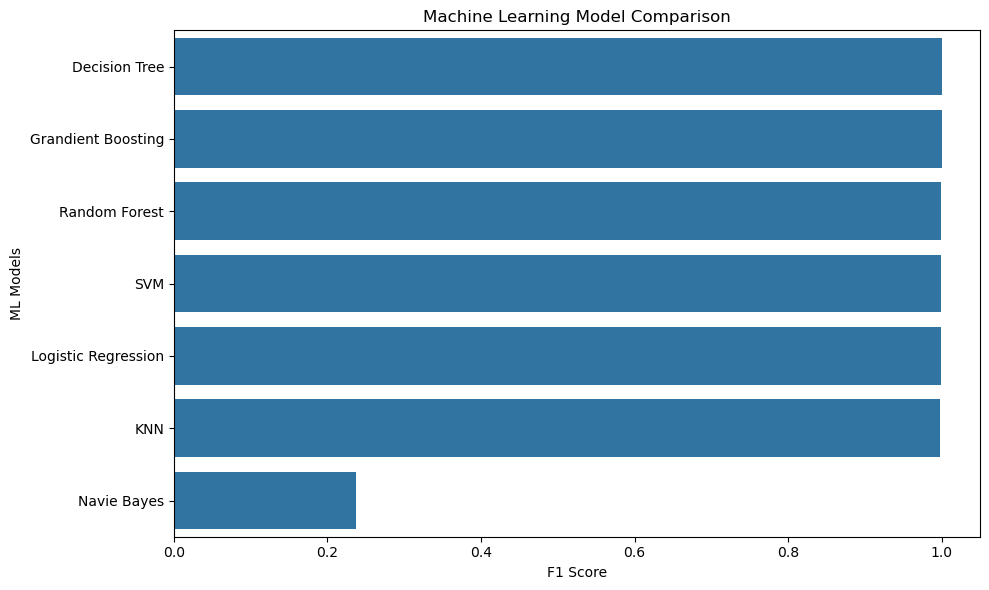

In [76]:
# ================================
# MODEL COMPARISON VISUALIZATION
# ================================

plt.figure(figsize=(10,6))
sns.barplot(
    data=evaluation_df,
    x="F1 Score",
    y="Models"
)
plt.title("Machine Learning Model Comparison")
plt.xlabel("F1 Score")
plt.ylabel("ML Models")
plt.tight_layout()
plt.show()

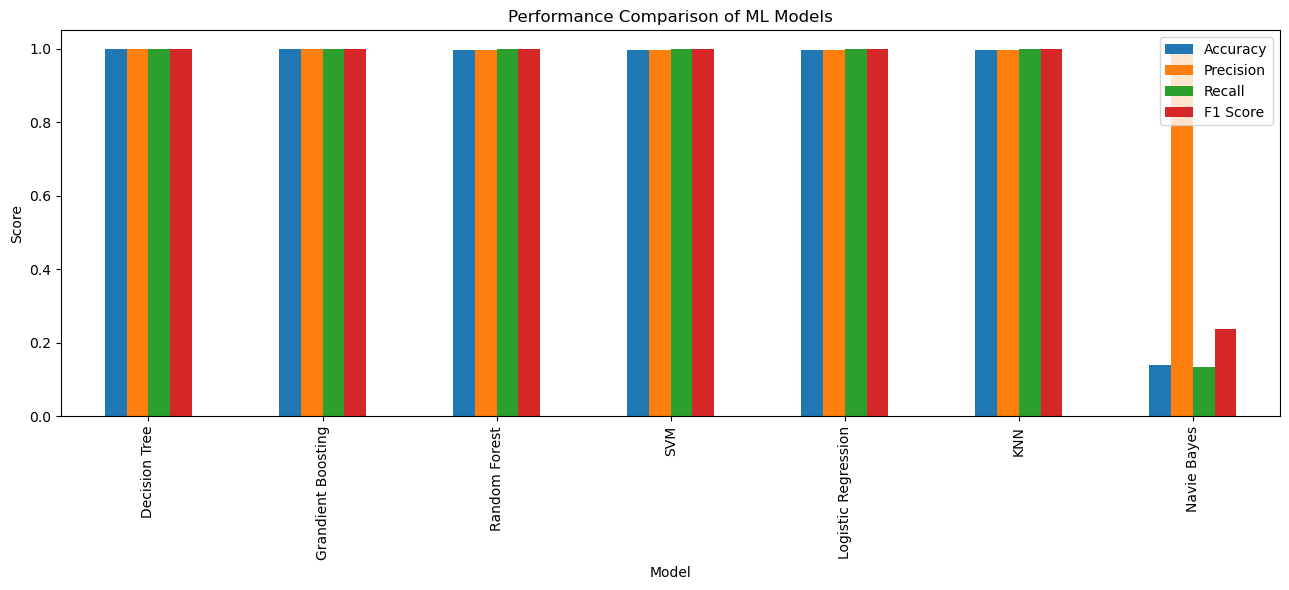

In [77]:
# ===========================
# ALL METRICS COMPARISON
# ===========================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
]
evaluation_df.set_index("Models")[metrics].plot(
    kind="bar",
    figsize=(13,6))
plt.title("Performance Comparison of ML Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.tight_layout()
plt.show()


In [89]:
# ===============
#  best model
# =============== 

best_model_name = evaluation_df.iloc[0]["Models"]
best_model = trained_models[best_model_name]

y_pred=best_model.predict(X_test)

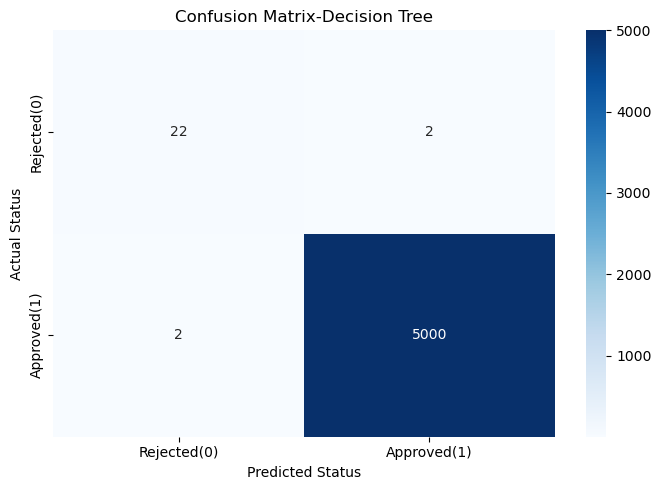

In [90]:
# ===================
# CONFUSION MATRIX
# ===================

cm = confusion_matrix(y_test,y_pred,labels=[0,1])
plt.figure(figsize=(7,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected(0)", "Approved(1)"],
    yticklabels=["Rejected(0)","Approved(1)"]
)
plt.title(f"Confusion Matrix-{best_model_name}")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.tight_layout()
plt.show()

In [96]:
# ===========================
# SAVE BEST MODEL
# ===========================

import joblib
joblib.dump(
    best_model,
    "Credit_Card_Approval_Model.pkt"
)
print("Best Model Saved Successfully!")
print("Model Name:", best_model_name)
print("File Name: Credit_Card_Approval_Model.pkl")

Best Model Saved Successfully!
Model Name: Decision Tree
File Name: Credit_Card_Approval_Model.pkl


In [97]:
loaded_model = joblib.load(
    "Credit_Card_Approval_Model.pkt"
)
print("Model loaded successfully!")

Model loaded successfully!


In [103]:
# New Applicant Details

new_application = pd.DataFrame([{
    "Application_Gender":1,
    "Owned_Car":1,
    "Owned_Realty":1,
    "Total_Children":1,
    "Total_Income": 250000,
    "Income_Type": "Working",
    "Education_Type": "Higher education",
    "Family_Status": "Married",
    "Housing_Type": "House / apartment",
    "Owned_Mobile_Phone": 1,
    "Owned_Work_Phone": 1,
    "Owned_Phone": 1,
    "Owned_Email": 1,
    "Job_Title": "Accountants",
    "Total_Family_Members": 3,
    "Applicant_Age": 32,
    "Years_of_Working": 6,
    "Total_Bad_Debt": 0,
    "Total_Good_Debt": 20
}])
# Predict Applicant Status
prediction = loaded_model.predict(new_applicant)[0]
# Get Prediction Probability
probability = loaded_model.predict_proba(
    new_applicant
)[0]
print("====================================")
print("CREDIT CARD APPROVAL PREDICTION")
print("====================================")

if prediction ==1:
    print("Predicted Status: Approved")
else:
    print("Predicted Status: REJECTED")

print("=====================================")
print("Prediction Probabilites:")

for class_label, prob in zip(
    loaded_model.classes_,probability
):
    status = "Rejected" if class_label == 0 else "Approved"
    print(f"{status}:{prob * 100:.2f}%")

CREDIT CARD APPROVAL PREDICTION
Predicted Status: Approved
Prediction Probabilites:
Rejected:0.00%
Approved:100.00%


In [100]:

print("====================================")
print("Prediction Probabilities:")

for class_label, prob in zip(
    loaded_model.classes_, probability
):
    status = "Rejected" if class_label == 0 else "Approved"
    print(f"{status}: {prob * 100:.2f}%")

print("====================================")

 CREDIT CARD APPROVAL PREDICTION
Predicted Status: APPROVED
Prediction Probabilities:
Rejected: 0.00%
Approved: 100.00%
